# Part 1. 추천 시스템 기초

## 1. 추천 시스템이란?

> **핵심** 사용자의 행동 기록과 아이템 정보를 바탕으로, 사용자가 좋아할 만한 아이템을 예측해 골라 주는 시스템

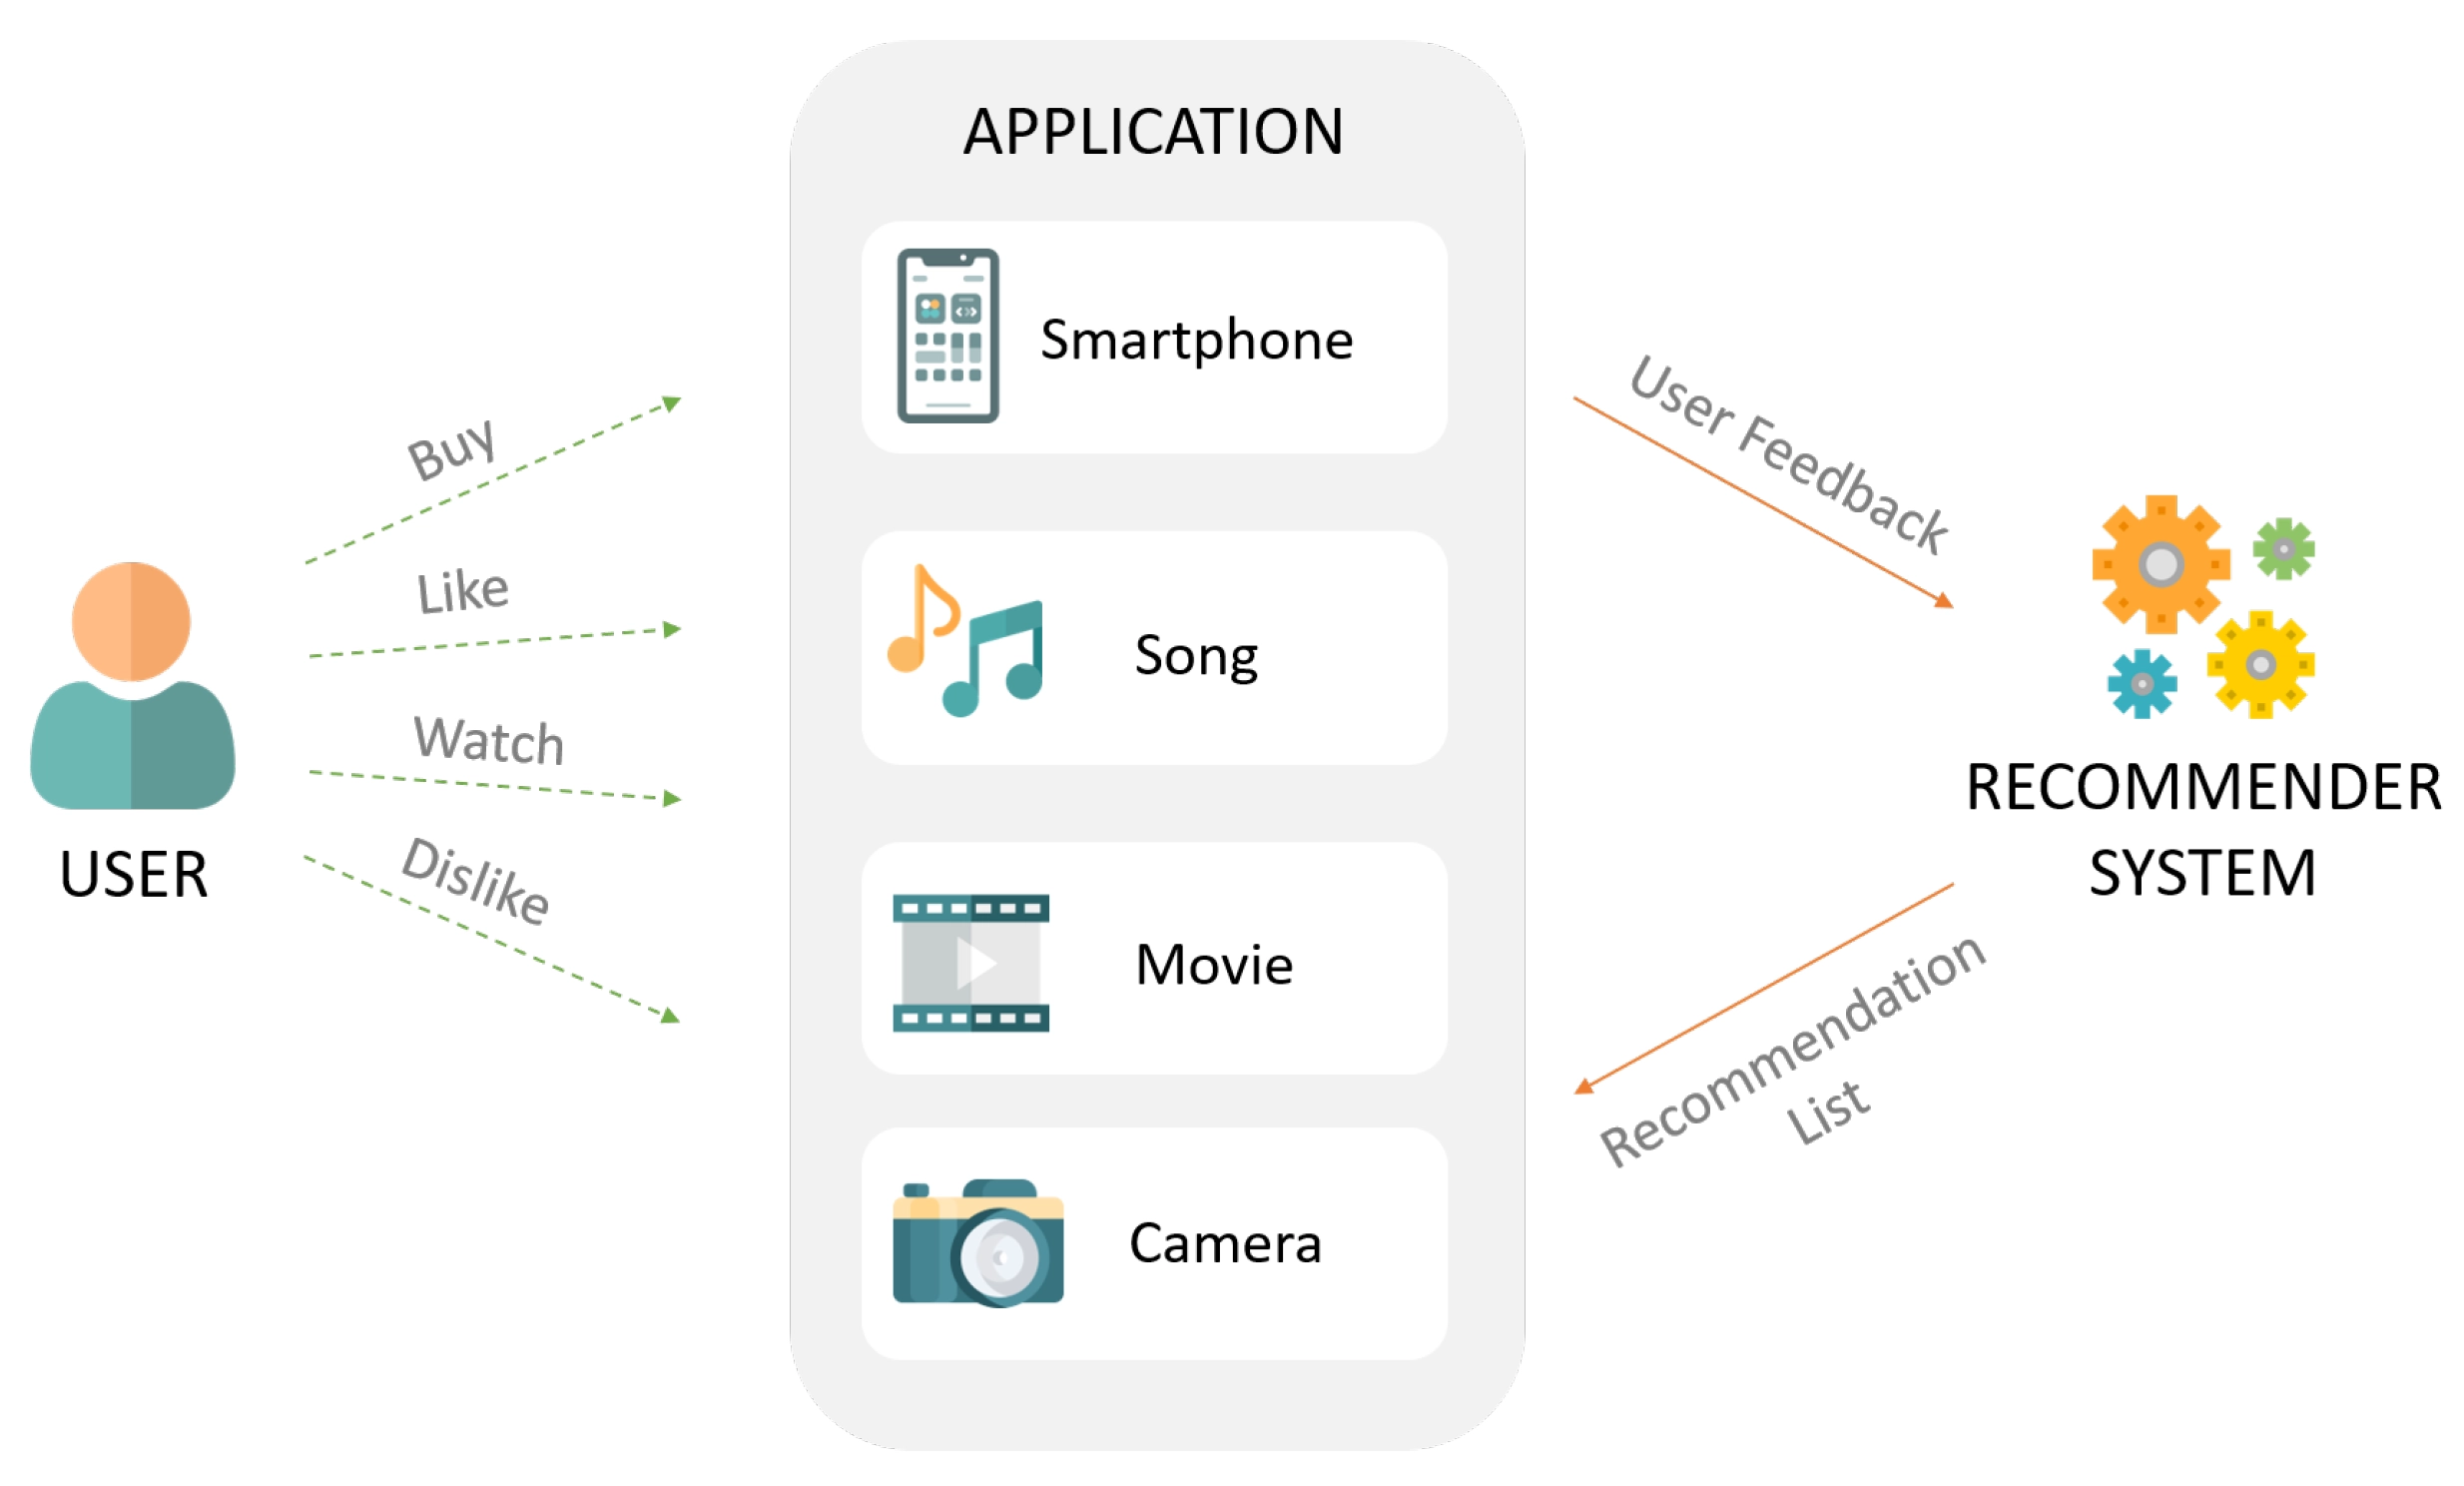
넷플릭스의 "회원님이 좋아할 만한 콘텐츠", 유튜브 다음 영상, 쇼핑몰의 "이 상품을 본 고객이 함께 본 상품"이 다 추천 시스템의 결과물임. 여기서 아이템은 상품, 영화, 음악, 뉴스, 앱 등을 모두 포함함.
- 고객 입장: 찾는 시간이 줄고, 몰랐던 취향의 아이템도 발견할 수 있음. **검색**이 이미 아는 걸 찾게 돕는다면 **추천**은 아직 모르는 걸 발견하게 도움
- 기업 입장: 이용 시간, 구매 전환, 재방문이 늘고, 잘 안 보이던 비인기 아이템도 노출할 수 있음

---

### 1-1. 사용되는 데이터의 종류

> **핵심** 사용자가 선호를 직접 표현한 명시적 데이터와, 행동에서 선호를 추측하는 암시적 데이터로 나뉨

- **명시적 데이터 (Explicit)**: 별점, 좋아요·싫어요, 리뷰처럼 사용자가 **직접 입력**한 데이터. 선호가 분명하다는 장점이 있지만, 평가를 남기는 사람 자체가 적고, 취향이 변할 수 있고, 사람마다 점수 기준이 다름
- **암시적 데이터 (Implicit)**: 조회수, 클릭, 구매, 시청 시간, 검색처럼 **행동에서 수집**한 데이터. 따로 입력하지 않아도 대량으로 쌓이지만, 행동이 곧 선호라고 단정할 수 없음. 잘못 클릭했거나 선물로 샀을 수 있고(좋아한다는 보장 X), 행동이 없어도 아직 못 봤을 수 있음(싫어한다는 보장 X)

실제 서비스에서는 암시적 데이터가 훨씬 많아서 둘을 섞어 쓰는 경우가 대부분임.

---

### 1-2. 추천 시스템의 분류

> **핵심** 무엇을 근거로 추천하느냐에 따라 내용 기반, 협업, 하이브리드 필터링으로 나뉨

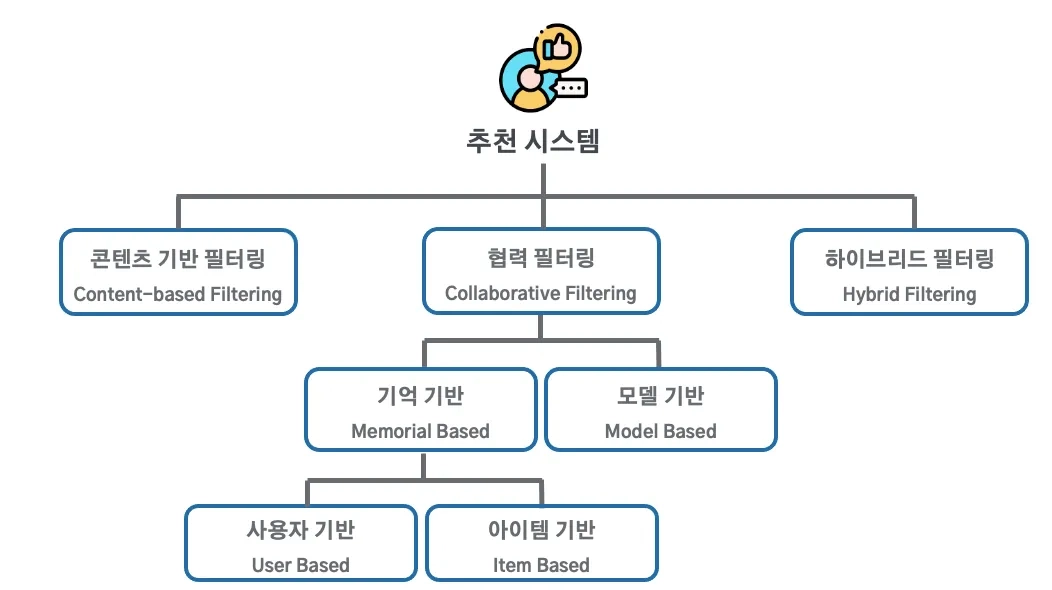

- **내용 기반 필터링**: 사용자가 선택한 아이템과 **특징이 비슷한 아이템**을 추천함. EX. SF 영화를 자주 봄 → 다른 SF 영화 추천
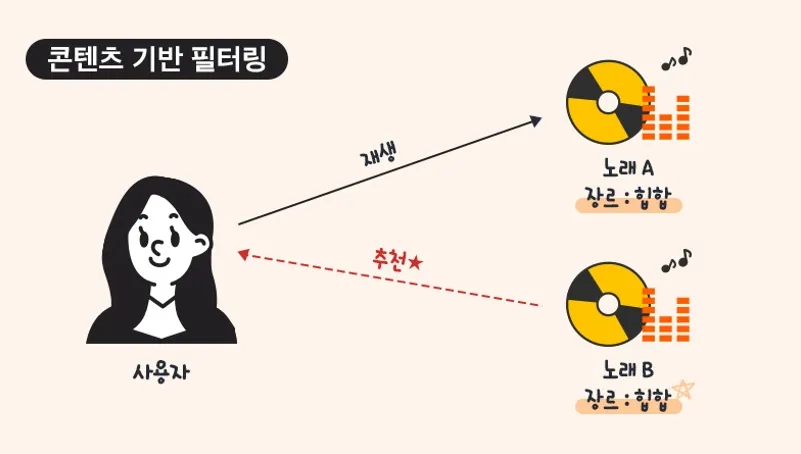
- **협업 필터링**: **다수 사용자의 선호도 정보**를 기반으로, 취향이 비슷한 사람이 좋아한 걸 나도 좋아할 거라고 봄
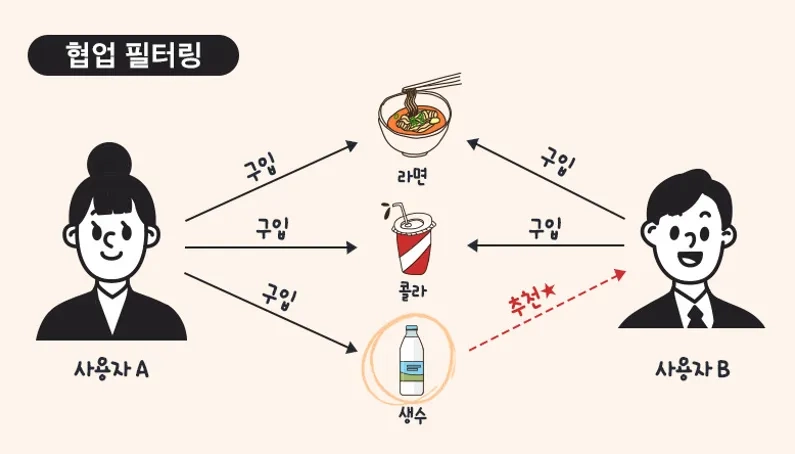
  - 사용자 기반: A와 B가 둘 다 라면, 콜라를 샀으면 → A가 산 생수를 B에게 추천 (비슷한 **사용자**가 좋아한 것)
  - 아이템 기반: 콜라를 좋아한 사람들이 생수도 자주 샀으면 → 콜라와 생수는 비슷한 아이템 → 콜라를 좋아하는 B에게 생수 추천 (선호한 것과 비슷한 **아이템**)
- **하이브리드 필터링**: 여러 알고리즘을 조합해 서로의 단점을 보완함. EX. 오늘 공개된 영화는 평점이 없어 협업 필터링으로 추천할 수 없으니, 처음엔 장르·감독 정보로 내용 기반 추천을 하다가 평점이 쌓이면 협업 필터링으로 넘어감 → 상황에 따라 골라 쓰는 **Switch** 방식. 이 밖에 결과를 합치는 Weighted Ensemble, 여러 결과를 함께 보여주는 Mixed, feature를 모두 조합하는 Feature Combination, 첫 모델이 다음 모델의 입력이 되는 Meta-Level이 있음
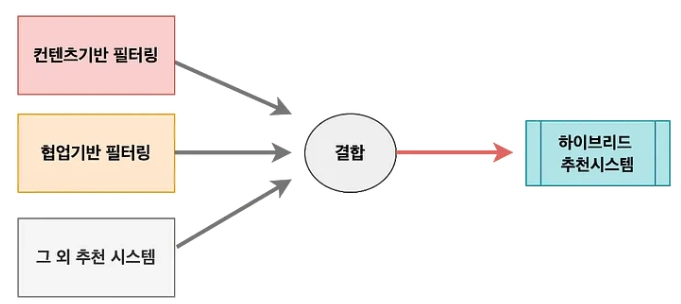
---

## 2. 내용 기반 필터링

> **핵심** 아이템을 숫자로 표현 → 사용자 프로필 생성 → 유사도 계산 → 점수가 높은 아이템 추천

### 2-1. 사용자 프로필

> **핵심** 사용자가 어떤 특성을 좋아하는지 정리한 정보로, 좋은 프로필일수록 추천 정확도가 높아짐

프로필은 가입할 때 좋아하는 장르를 고르게 하는 **직접 지정형**과, 과거 행동에서 취향을 추론하는 **간접 지정형**으로 얻을 수 있음. 구체적인 방법은 세 가지임.
1. **본 아이템들의 특성 가중치 평균**: 어벤져스 [0.9, 0.1, 0.5, 0.0], 인터스텔라 [0.3, 0.2, 0.9, 0.0], 노트북 [0.0, 0.9, 0.0, 0.1](액션·로맨스·SF·공포)을 본 사용자의 프로필은 평균인 [0.4, 0.4, 0.47, 0.03] → SF를 가장 좋아하고 공포는 거의 안 좋아함. 새 영화 "듄" [0.4, 0.0, 0.9, 0.0]과 코사인 유사도가 약 0.8로 높으니 추천!
2. **설문, 키워드, 평가로 따로 파악**: 좋아요·평점 같은 명시적 피드백, 검색·구매·북마크 같은 암시적 피드백 활용
3. **분류 문제로 해결**: 아이템 특징을 입력, 유저의 기존 평가를 정답으로 두고 새 아이템에 줄 평가를 예측 → 결정 트리, 랜덤 포레스트, KNN 등 적용 가능

---

### 2-2. 유사도 (Similarity)

> **핵심** 아이템과 사용자를 같은 feature의 숫자 벡터로 바꾼 뒤, 얼마나 비슷한지 계산해 유사도가 높은 아이템을 추천함

먼저 장르, 국가, 감독 같은 아이템 속성을 표로 정리하고, 원-핫 인코딩으로 속하면 1, 아니면 0인 벡터로 바꿈. 사용자도 같은 n개의 feature로 표현하면 둘을 비교할 수 있음. 가장 기본은 **내적**으로, 같은 위치 값끼리 곱해 더한 값이 클수록 비슷함.

유사도 방식은 집합 기반 **자카드 유사도**(교집합 크기), 각도 기반 **코사인 유사도**, 거리 기반 **유클리디안 거리**, 상관관계 기반 **피어슨 상관계수**가 있음.
- **코사인 유사도**: 내적을 두 벡터의 길이로 나눈 값. 길이는 무시하고 **방향만** 봐서 [1, 1]과 [5, 5]도 1이 됨. 거리처럼 쓰려면 1에서 빼서 코사인 거리로 씀

$$
\cos(A, B) = \frac{A \cdot B}{\|A\| \, \|B\|}
$$

- **유클리드 거리**: 두 점 사이 거리로, 작을수록 비슷함

내적이냐 코사인이냐에 따라 결과 성격이 달라짐. 내적은 길이까지 반영해서 장르가 많은 영화처럼 feature가 많은 아이템이 유리해지고, 코사인은 그 쏠림은 줄이지만 정보가 풍부하다는 점은 반영하지 못함.

---

### 2-3. TF-IDF

> **핵심** 특정 문서에는 자주 나오고 다른 문서에는 드문 단어에 높은 값을 줘서, 텍스트를 의미 있는 숫자로 바꾸는 방법

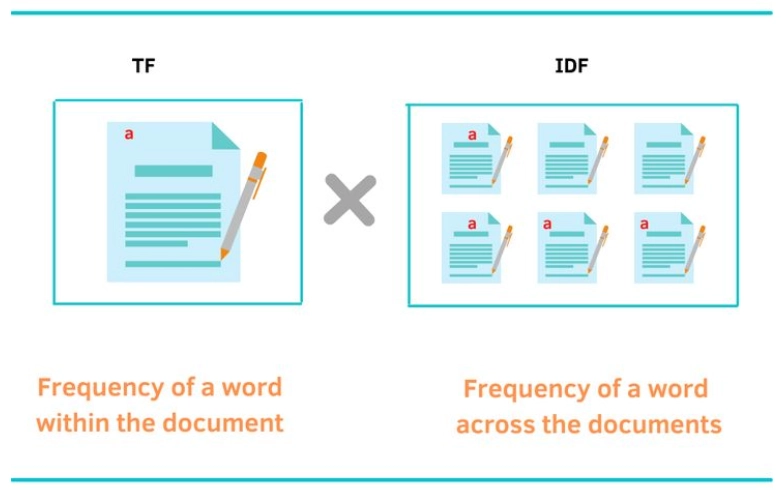

줄거리나 상품 설명 같은 텍스트도 중요한 특징인데, 단어 개수만 세면 "그리고", "있다"처럼 어디에나 나오는 단어가 가장 중요해 보이는 문제가 있음.
- **TF**: 특정 문서에 그 단어가 많이 나올수록 커짐
- **IDF**: 그 단어가 등장한 문서 수가 많을수록 작아짐

$$
idf(d,t) = \log\left(\frac{n}{1+df(t)}\right), \qquad TF\text{-}IDF = TF \times IDF
$$

EX. "고양이는 귀엽다", "강아지는 귀엽다", "고양이는 사냥한다" 세 문서에서 "귀엽다"는 두 문서에 나와 IDF가 log(3/3) = 0이라 중요도 0, "사냥한다"는 한 문서에만 나와 log(1.5) ≈ 0.176으로 더 중요한 단어가 됨.

추천에서는 영화 줄거리를 TF-IDF 벡터로 바꾸고, 재밌게 본 영화와 코사인 유사도를 비교해 높은 영화를 추천함. "우주", "탐사"가 중요한 영화를 좋아한 사람에겐 그 단어들이 비슷하게 중요한 다른 SF 영화가 추천되는 식임.

---

### 2-4. 내용 기반 필터링의 장단점

> **핵심** 신규 아이템도 추천할 수 있고 이유를 설명하기 쉽지만, 비슷한 것만 추천하고 신규 사용자는 어려움

- 장점: 속성만 있으면 신규 아이템도 추천 가능(**아이템 콜드 스타트 해결**), 다른 사용자의 데이터가 필요 없음, 어떤 feature 때문에 추천했는지 **설명하기 쉬움**
- 단점: 속성 정보가 부족하면 정확도가 떨어짐, **비슷한 것만 계속 추천**(과도한 특화)해서 새 장르 발견이 어려움, 기록 없는 **신규 사용자**는 추천하기 어려움

**콜드 스타트**는 정보가 충분하지 않아 적절한 추천을 못 하는 문제인데, 아이템 콜드 스타트는 내용 기반으로 해결할 수 있지만 사용자 콜드 스타트는 내용 기반으로도 어려움.

---

## 3. 협업 필터링

> **핵심** 과거에 비슷한 선호를 가진 사용자들은 앞으로도 비슷한 선호를 가질 거라는 가정에서 출발함

### 3-1. 메모리 기반 협업 필터링

> **핵심** 별도 학습 없이 저장된 평점에서 비슷한 사용자나 아이템(이웃)을 찾아 평점을 예측함

저장된 평점을 그대로 꺼내 쓰고 "이웃"을 찾아 예측해서 **이웃 기반 협업 필터링**이라고도 함.

**사용자 기반 (User-based)**
나와 유사도가 높은 사용자 TOP-N명을 이웃으로 골라, 이웃들의 평점을 **유사도로 가중평균**해 내가 안 본 아이템의 평점을 예측함. 평점 데이터에서는 유사도로 **피어슨 상관계수**를 많이 씀.

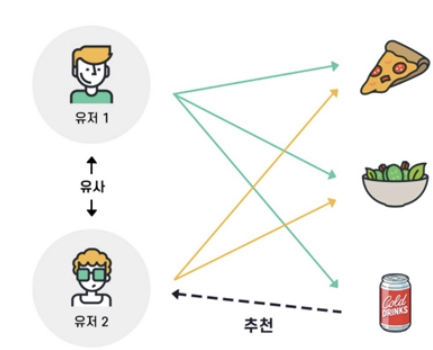

EX. A는 어바웃타임 5, 노팅힐 4, 아이언맨 1점이고, B는 5, 5, 2점에 라라랜드 5점, C는 1, 2, 5점에 라라랜드 2점을 줌 → A와 B는 패턴이 거의 같아 유사도 약 0.97, A와 C는 정반대라 -1 → B는 라라랜드를 자기 평균보다 0.75점 높게, C는 0.5점 낮게 줬으니 이걸 유사도만큼 반영해 A의 평균(약 3.33)에 더하면 약 3.96점 → **A에게 라라랜드 추천!**

$$
\hat{r}_{ui} = \bar{r}_u + \frac{\sum_{v} sim(u, v)\,(r_{vi} - \bar{r}_v)}{\sum_{v} |sim(u, v)|}
$$

**아이템 기반 (Item-based)**
내가 평가한 아이템과 **평점 패턴이 비슷한 아이템**을 찾음. 속성이 아니라 사람들이 함께 좋아하고 싫어한 패턴으로 유사도를 판단함. EX. 어바웃타임을 높게 준 A, B가 노팅힐도 높게 줬으면 둘은 비슷한 아이템 → 어바웃타임을 좋아하는 D에겐 노팅힐 추천, 낮게 준 C에겐 추천 X. 아이템끼리 관계는 덜 변해서 유사도를 **미리 계산해 두고 재사용**하기 좋음.

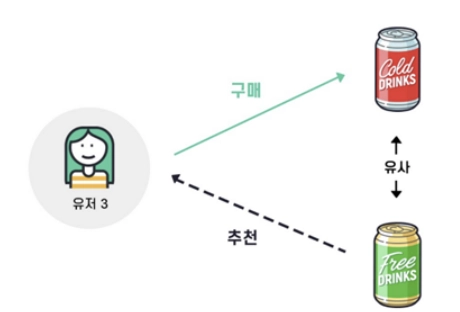

| 기준 | 사용자 기반 | 아이템 기반 |
| --- | --- | --- |
| 정확성 | 아이템 수가 사용자 수보다 많을 때 유리 | 사용자 수가 아이템 수보다 많을 때 유리 |
| 계산 속도 | 추천할 때마다 비슷한 사용자를 새로 찾음 | 미리 계산해 두고 재사용해서 빠름 |
| 다양성 | 독특한 아이템까지 추천해 의외성이 강점 | 기존과 비슷한 추천이 많아 다양성은 부족 |
| 활용 예 | 뉴스, SNS 친구 추천, 음악 | 아마존 등 사용자가 많은 대형 플랫폼 |

사용자가 많으면 아이템 기반이 유리한 이유는, 두 사용자가 함께 평가한 아이템은 적어도 두 아이템을 함께 평가한 사용자는 많을 가능성이 높기 때문임. 정답이 있는 건 아니고, 새로운 추천이 필요하면 사용자 기반, 정확하고 안정적인 추천이 중요하면 아이템 기반을 쓰는 경향이 있음.

---

### 3-2. 메모리 기반 협업 필터링의 한계

> **핵심** 데이터가 희소하고, 신규 사용자·아이템은 추천이 어렵고, 규모가 커질수록 계산량이 폭증함

- **희소 행렬 문제**: 실제 사용자-아이템 행렬은 대부분 비어 있음. 넷플릭스 프라이즈 데이터는 약 48만 명 × 1만 8천 편 = 85억 칸 중 평점이 약 1억 개라 **99%가 빈칸**. 함께 평가한 아이템이 적으면 유사도를 믿기 어렵고, 이웃을 못 찾으면 예측 자체가 어려움 → **모델 기반 협업 필터링**으로 해결
- **콜드 스타트 문제**: 행동 기록에만 의존해서 신규 사용자는 이웃을 못 찾고, 신규 아이템은 누가 처음 평가하기 전까진 추천 후보에 못 오름(**first-rater 문제**) → 가입 시 취향을 직접 고르게 하기, 내용 기반과 섞은 하이브리드, 같은 카테고리 임베딩 평균으로 임시 표현, 나이·성별 같은 인구통계 정보 활용
- **확장성 문제**: 예측할 때마다 그 아이템을 평가한 모든 사용자와 유사도를 구해야 해서 규모가 커질수록 계산량이 늘어남 → 유사도가 높은 **k명의 이웃만** 쓰는 **KNN 협업 필터링**. k가 너무 작으면 소수 의견에 흔들리고, 너무 크면 덜 비슷한 사람까지 섞여 흐려짐

---

### 3-3. 모델 기반 협업 필터링

> **핵심** 관측된 평점으로 모델을 미리 학습해 두고, 사용자와 아이템을 잠재 요인 벡터로 나타내 그 내적으로 빈칸을 예측함

메모리 기반이 추천할 때마다 원본 평점을 직접 비교한다면, 모델 기반은 평점을 **압축된 모델로 요약**해 두고 그 모델로 추천함. 학습 단계(미리, 주기적으로)와 예측 단계(추천 시점에 빠르게)로 나뉨. 평점 이면의 **잠재된 패턴**을 학습해서 직접 겹치는 평가가 없어도 빈칸을 추정할 수 있음.

**잠재 요인 (Latent Factor)**
평점에 직접 드러나지 않지만 사용자와 아이템의 관계를 결정짓는 **숨은 특성**으로, "취향" 같은 개념을 숫자로 표현함. **Latent Factor Model**은 사용자와 아이템을 같은 잠재 공간의 벡터로 놓는데, 액션·로맨스처럼 축의 의미를 사람이 정하는 Factor Model과 달리 **축의 개수(k)만 정하고 의미는 학습으로 정해져서** 사람이 해석하기 어려움.

**행렬 분해 (Matrix Factorization)**
큰 평점 행렬을 **작은 행렬 두 개의 곱**으로 쪼갬. 사용자 잠재 요인 행렬 P와 아이템 잠재 요인 행렬 Q로 나누고, 예측 평점은 두 벡터의 내적임.
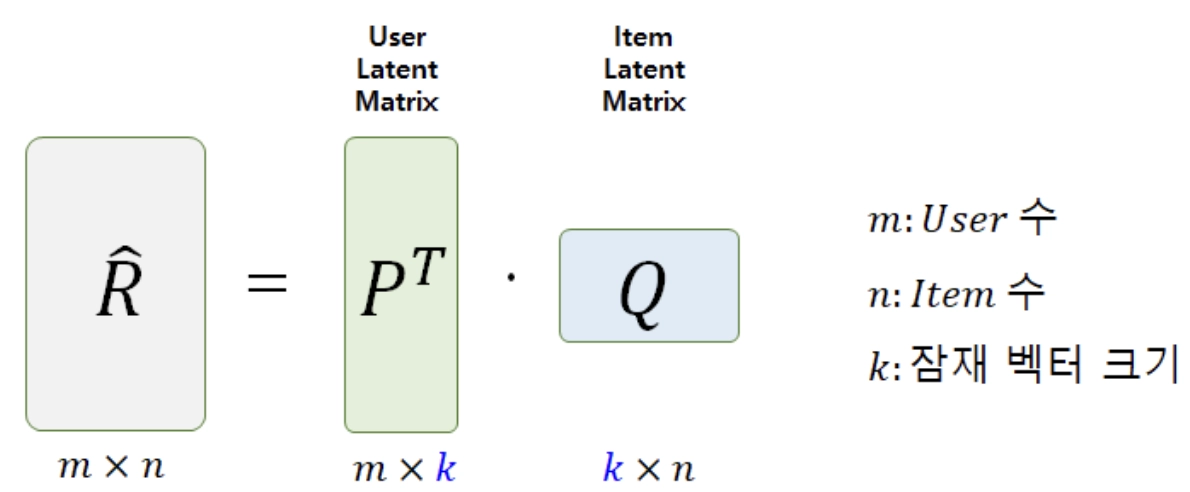
$$
\hat{r}_{ui} = p_u^T q_i
$$

EX. 요인이 (로맨스, 액션)일 때 사용자 (0.9, 0.2)와 노팅힐 (0.8, 0.1)의 내적은 0.74, 존 윅 (0.1, 0.9)은 0.27 → 노팅힐 추천. 단 실제 잠재 요인은 이렇게 깔끔하게 해석되지 않는 경우가 대부분임.

학습은 k를 정하고 → 벡터를 임의로 시작해서 → **평점이 있는 칸만** 예측해 실제와의 오차를 구하고 → 오차가 줄도록 벡터를 조금씩 고치는 걸 반복함. 손실 함수는 (실제 - 예측)² 합에 벡터 크기 규제(λ)를 더해 과적합을 막음. 벡터를 고치는 방법은 평점을 하나씩 보며 수정하는 **SGD**, 사용자·아이템 벡터를 번갈아 고정하는 **ALS**(병렬 처리에 유리)가 있음.

사람마다 점수 기준이 다르고 평이 좋은 영화도 있으니 **편향 항**을 더하기도 함. EX. 전체 평균 3.7, 타이타닉은 평균보다 +0.5, 깐깐한 Joe는 −0.3 → Joe의 타이타닉 기본 예측은 3.9점. 편향이 경향을 먼저 설명하면 잠재 요인은 둘이 얼마나 잘 맞는지에만 집중할 수 있음.

$$
\hat{r}_{ui} = \mu + b_i + b_u + p_u^T q_i
$$

행렬 분해 방식으로는 수학적으로 분해하는 **SVD**(희소 행렬엔 결측치 처리 필요), 관측된 평점만 학습하는 **학습 기반 MF**, 음수가 안 되게 제약해 해석력을 높인 **NMF**, 확률적으로 접근하는 **PMF**가 있음.

| 구분 | 메모리 기반 | 모델 기반 |
| --- | --- | --- |
| 예측 방식 | 비슷한 사용자·아이템을 직접 찾음 | 학습한 벡터를 내적 |
| 확장성 | 추천마다 유사도 계산이 많음 | 학습은 미리, 추천 땐 내적만 → 빠름 |
| 콜드 스타트 | 해결 어려움 | 해결 어려움 (상호작용 없으면 벡터 학습 불가) |
| 장점 | 추천 이유를 설명하기 쉬움 | 데이터를 압축해 빠르고 일반화에 유리 |

결국! 행렬 분해는 희소성과 확장성을 많이 해결했지만 **내적이라는 선형 계산**으로 예측한다는 한계가 남음 → Part 2에서 딥러닝으로 넘어섬

---

# Part 2. 딥러닝 기반 추천 시스템

## 1. VAE 기반 협업 필터링

> **핵심** 사용자의 상호작용 기록을 신경망으로 확률분포로 압축했다가 복원하면서, 아직 안 본 아이템의 선호를 예측하는 모델

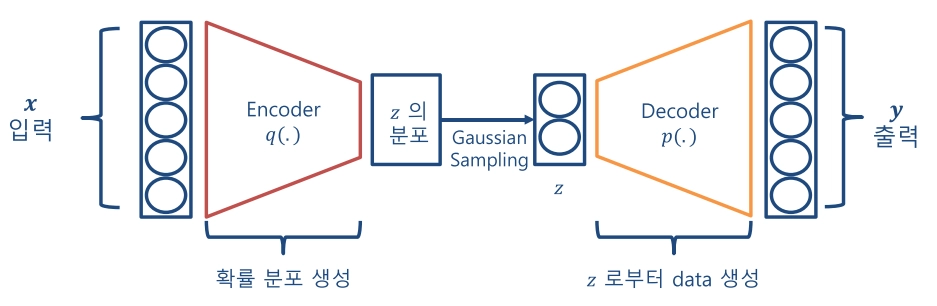

### 1-1. MF의 한계와 딥러닝의 등장

> **핵심** MF는 선형이라 복잡한 조합을 못 잡고, 사용자를 점 하나로 표현해 불확실성을 무시함

- **선형성**: 내적은 요인별로 곱해서 더하기만 해서 요인끼리 얽히는 효과를 못 잡음. EX. 로맨스도 좋고 음악 영화도 좋은데 뮤지컬 로맨스는 별로인 사용자 → 내적에선 둘 다 높은 영화가 오히려 최고점을 받음 → 비선형 활성화 함수를 가진 **신경망**으로 해결
- **불확실성 무시**: 사용자마다 벡터를 하나만 학습하는 **점 추정**이라, 기록이 5개인 사용자와 5,000개인 사용자를 똑같이 확신함 → **평균과 분산을 함께 출력**해서 해결

이 두 한계를 극복하려고 도입된 게 **VAE**임.

---

### 1-2. WHY AE가 아닌 VAE일까?

> **핵심** AE도 사용자를 점 하나로 표현하지만, VAE는 분포(평균·표준편차)로 표현해서 기록이 적은 사용자에게도 안정적임

**오토인코더(AE)**는 입력을 작은 벡터로 압축했다가 복원하는 모델로, 입력 자체가 정답이고 복원에 꼭 필요한 핵심 정보만 남기도록 학습함. 오토인코더를 협업 필터링에 처음 적용한 AutoRec에서는 은닉층을 선형으로만 쓰면 RMSE 0.872, sigmoid를 쓰면 0.831로 **비선형성**이 성능을 높일 수 있음을 보여 줌. BUT AE도 사용자를 점 하나로 표현한다는 점은 MF와 같음.

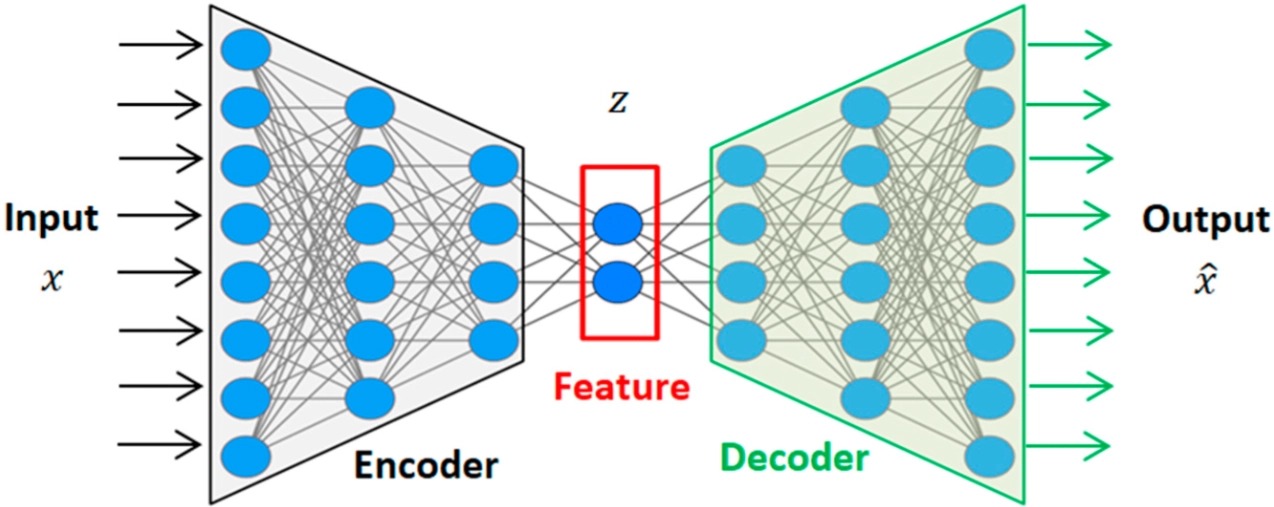

**VAE**는 가운데 잠재 벡터를 **분포**로 표현함. 평균 μ는 취향의 중심, 표준편차 σ는 그 위치를 얼마나 확신할 수 없는지(불확실성)를 뜻함. EX. 영화를 5편만 본 사용자를 AE는 z = [1.2, −0.7] 하나로 확정해서 우연히 본 공포 영화 같은 노이즈까지 반영하지만, VAE는 μ = [1.2, −0.7], σ = [0.8, 0.9]로 표현함.

VAE가 더 안정적인 이유는 두 가지임.
1. 학습 때마다 μ 근처에서 z를 무작위로 뽑아 넣어서, μ에서 조금 벗어나도 비슷한 추천이 나오도록 학습됨
2. KL 항이 분포를 표준정규분포 쪽으로 당겨서, 기록 몇 개만으로 극단적인 위치로 가기 어려움

---

### 1-3. Mult-VAE의 작동 구조

> **핵심** 상호작용 기록(0/1 벡터)을 인코더로 분포(μ, σ)로 요약하고, 디코더로 전체 아이템의 선호 확률을 복원해 추천함

| 구성 요소 | 세부 내용 |
| --- | --- |
| 입력 | 아이템 수만큼 긴 0/1 벡터 (평점은 4점 이상만 1) |
| 인코더 | 평균 μ와 표준편차 σ를 출력 |
| 잠재 벡터 z | μ, σ로 정해진 정규분포에서 샘플링 |
| 디코더 | 모든 아이템 점수를 계산한 뒤 softmax로 확률 변환 → 확률이 높은 순으로 추천 |

---

### 1-4. VAE의 비밀 병기 -> 목적 함수와 KL Divergence

> **핵심** ELBO를 최대화하면서 정확한 복원과 잠재 공간 정규화를 동시에 챙김

목적 함수 **ELBO**는 두 항으로 이루어짐.
1. **복원 항**: 디코더가 z로 원래 입력을 최대한 비슷하게 복원하게 함 (AE와 같은 역할)
2. **KL Divergence 항**: 인코더가 낸 분포가 표준정규분포에서 크게 벗어나지 않게 해서, 과적합을 막고 잠재 공간을 **연속적이고 부드럽게** 유지함

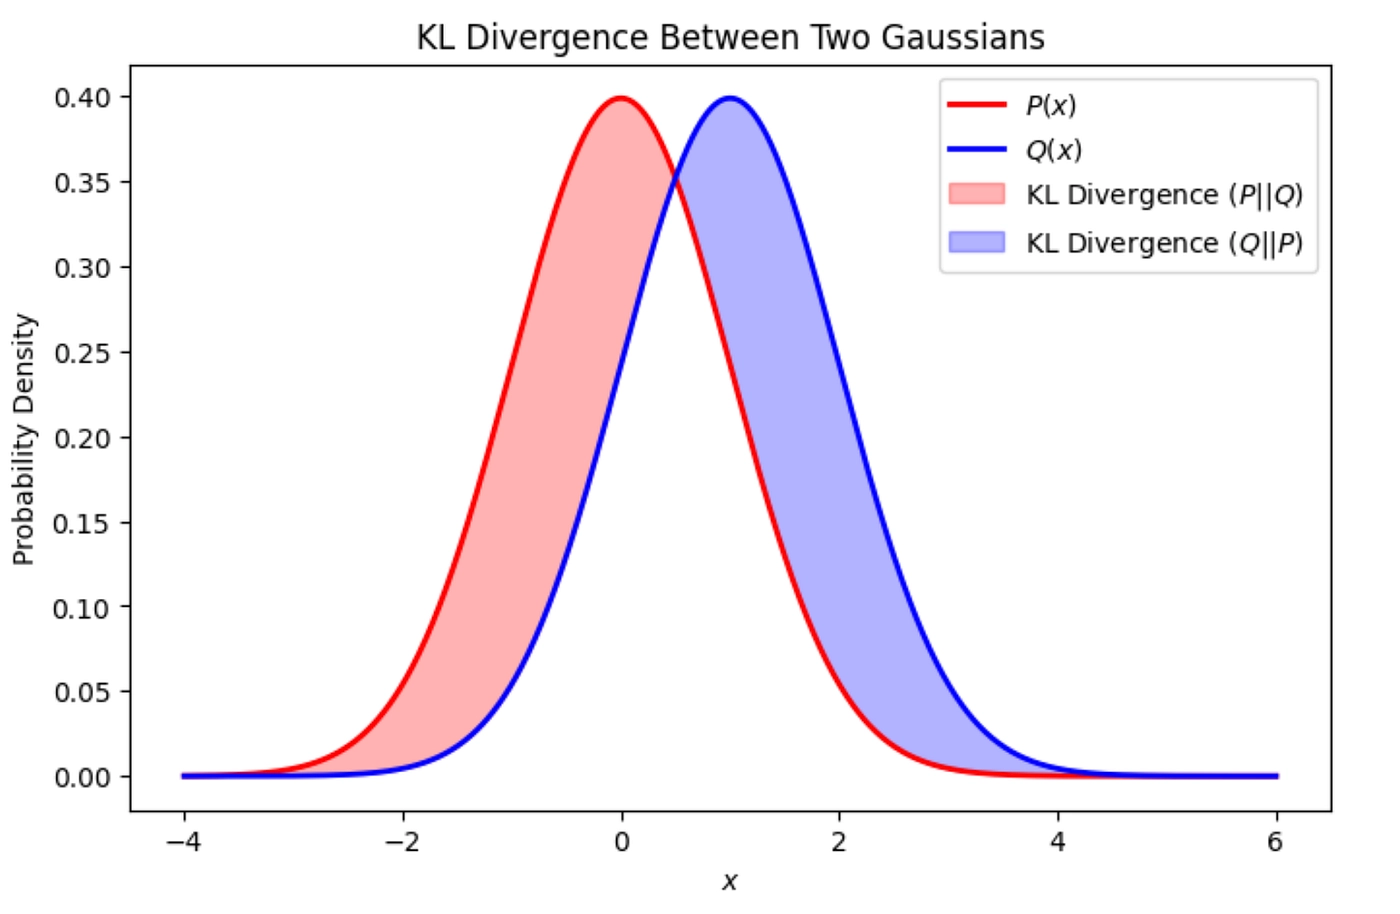
시험 공부로 치면 1번은 "기출을 많이 풀어라", 2번은 "기본 개념에서 벗어나지 마라"임. 1번만 있으면 기출 답만 외워 새 문제를 못 풀고, 2번만 있으면 모든 문제에 같은 답을 쓰게 됨.

**KL Divergence**는 두 확률분포가 얼마나 다른지를 나타내는 값으로, N(0, 1)과 같으면 0이 되고 중심에서 멀어지거나(μ = 2면 2.0) 너무 좁게 확신하거나(σ = 0.1이면 약 1.81) 너무 넓게 퍼지면(σ = 3이면 약 2.90) 벌점이 커짐.
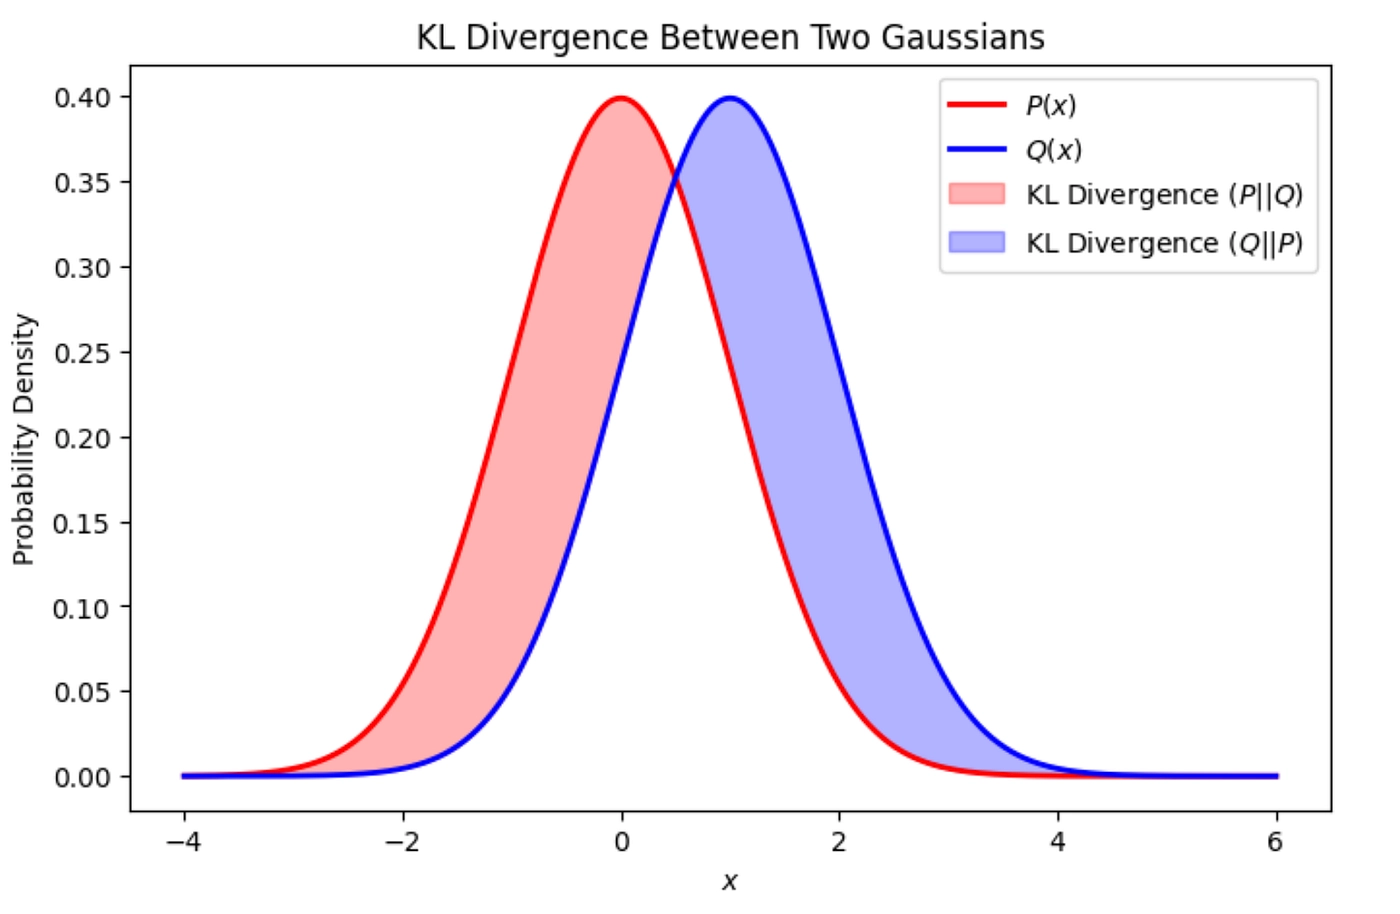

$$
D_{KL}\big(\mathcal{N}(\mu, \sigma^2) \,\|\, \mathcal{N}(0, 1)\big) = \frac{1}{2}\left(\mu^2 + \sigma^2 - \ln \sigma^2 - 1\right)
$$

그래서 AE는 사용자 벡터가 듬성듬성 흩어지고 빈 공간이 학습되지 않지만, VAE는 사용자들이 중심 근처에 연속적으로 모임. 기록이 적은 사용자도 근거가 부족한 만큼 중심 쪽으로 당겨져 비슷한 사용자들 근처에 놓이고, 기록이 많은 사용자들의 패턴을 함께 활용할 수 있음 → VAE-CF가 **희소한 데이터에 강한** 이유임!
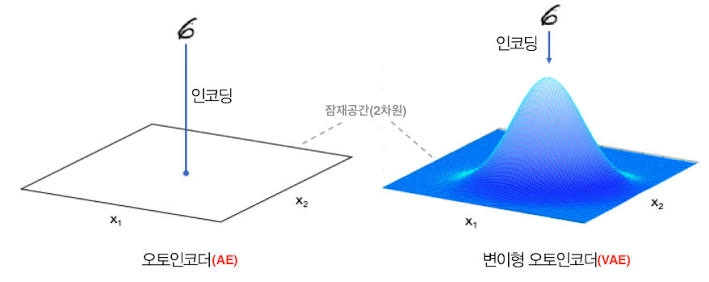
---

## 2. GNN 기반 사용자 선호 예측

> **핵심** CF, MF, VAE는 상호작용을 행렬의 칸 하나로만 다뤄서 이어진 관계를 못 씀 → 관계 자체를 그래프로 보고 학습하자
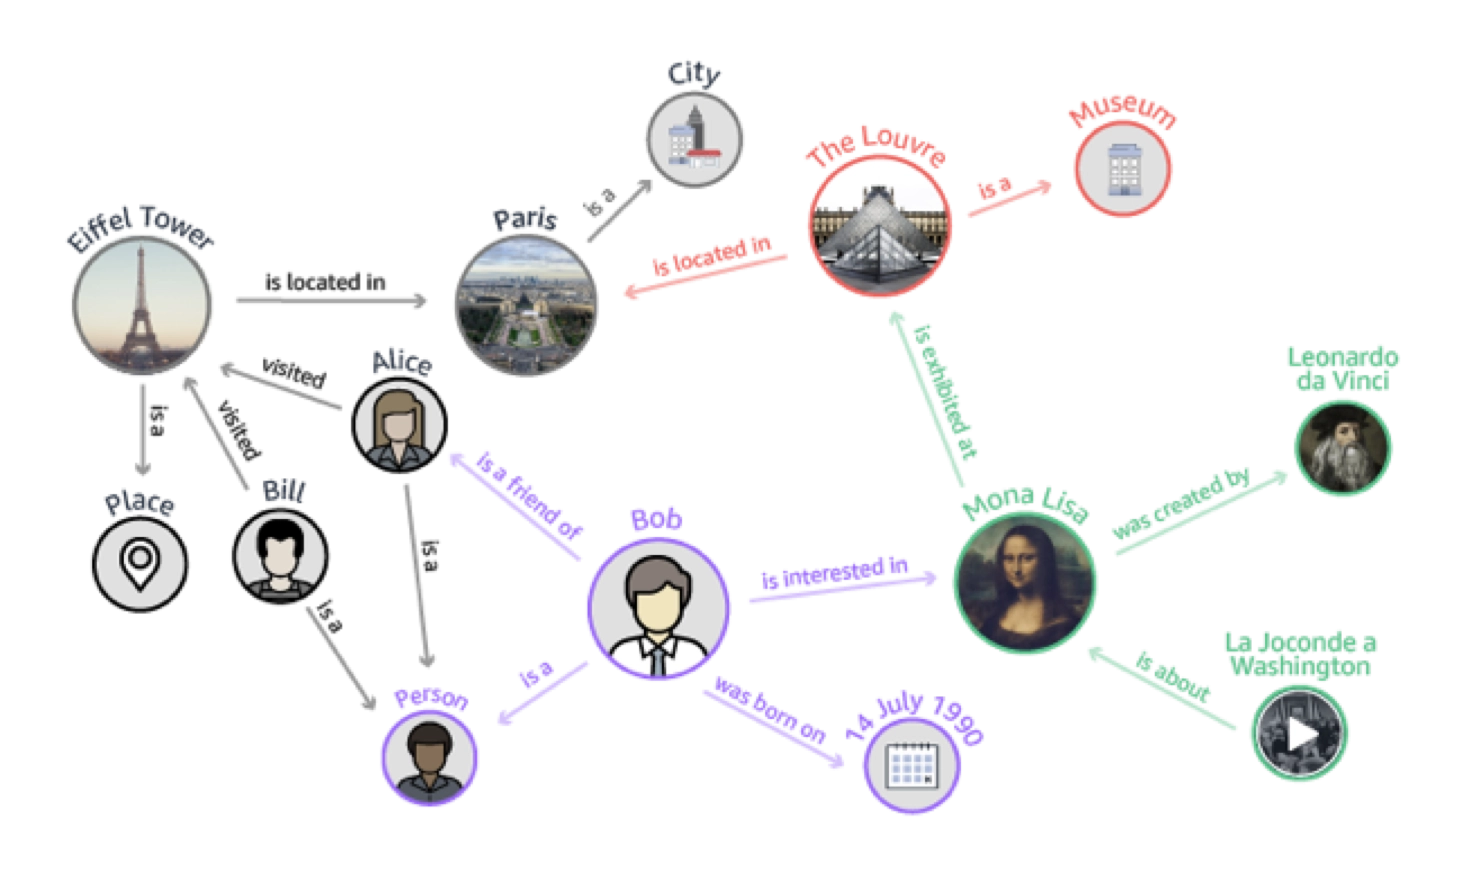

"A가 영화 X를 봤다"는 행렬의 칸 하나지만, "A가 본 영화를 B도 봤고 B는 Y도 봤다"처럼 이어진 관계는 칸만으로는 직접 활용할 수 없음. 게다가 이 모델들은 행동의 순서도 고려하지 않음.

### 2-1. GNN (그래프 신경망)

> **핵심** 사용자와 아이템을 점(노드), 행동을 선(엣지)으로 보면 행렬의 칸이 그래프의 경로가 됨

나 → 영화 X → X를 본 다른 사용자 → 영화 Y처럼 경로를 따라가면 "나와 비슷한 사람이 좋아한 다른 영화"를 자연스럽게 찾을 수 있음.

**그래프**는 노드(사용자, 아이템 같은 개체)와 엣지(관계, 상호작용)로 이루어진 자료 구조임. 엣지는 방향(팔로우)이나 가중치(평점 5점)를 가질 수 있음. 그래프를 쓰는 이유는 두 가지임.
1. "취향이 비슷하다" 같은 **추상적인 관계를 데이터로** 저장해서 관계 자체를 직접 학습할 수 있음
2. **Non-Euclidean 공간**도 다룰 수 있음. 이미지(격자)나 텍스트(일렬)는 이웃 구조가 고정돼서 CNN, RNN을 쓰지만, SNS·분자·추천 그래프는 노드마다 이웃 수가 제각각이고 순서나 좌표가 없음. 이걸 행렬로 억지로 펼치면 정보가 손실되니까 구조를 그대로 쓰는 GNN으로 학습함

---

### 2-2. GNN의 구조와 프로세스

> **핵심** 각 노드가 이웃의 정보를 받아 자기 임베딩을 갱신하는 메시지 패싱을 K번 반복해서, 이웃들의 취향까지 반영한 임베딩을 얻음
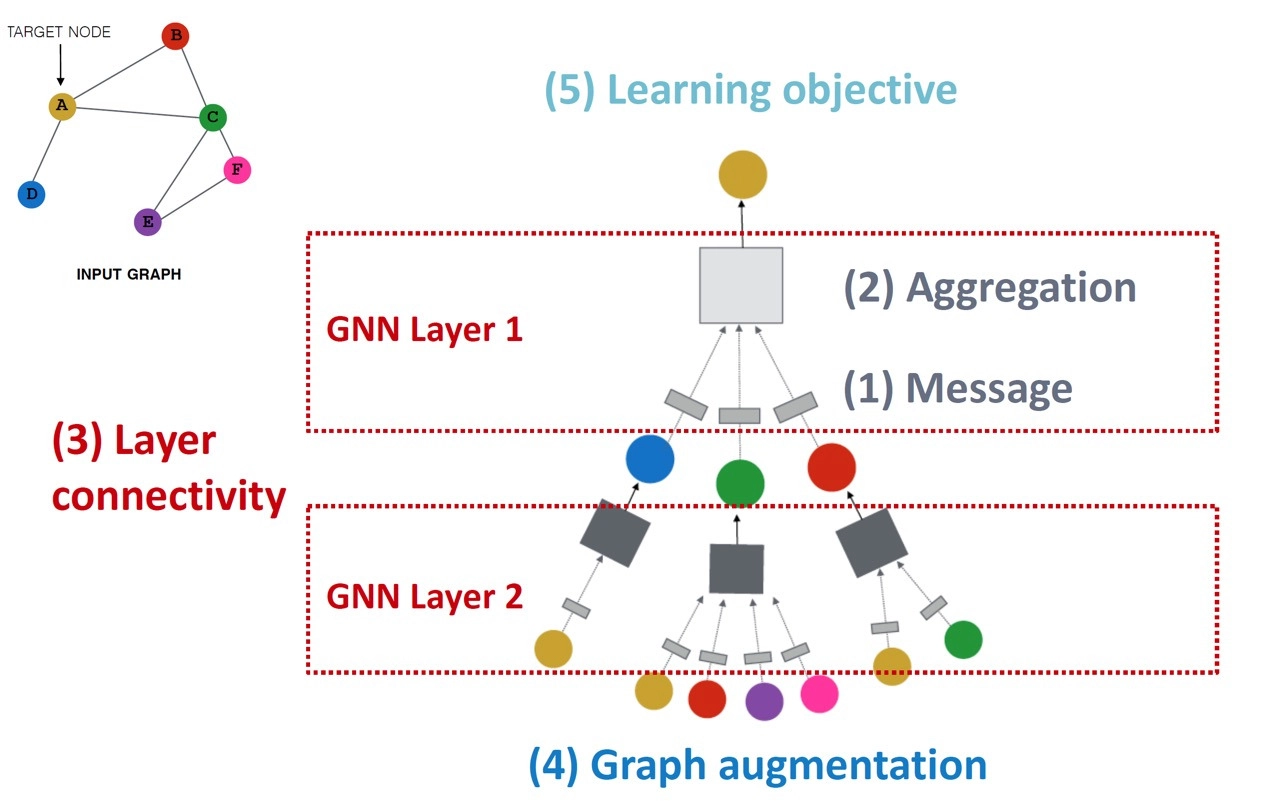
**1. 그래프 구조 생성**
노드와 엣지를 정의하고 각 노드에 초기 피처를 부여함. EX. U1이 A에 5점, B에 4점, U2가 A에 3점, C에 5점, U3가 C에 4점을 줬다면 → 노드는 사용자 3개 + 영화 3개, 엣지는 평점 기록 5개 → B — U1 — A — U2 — C — U3로 이어진 하나의 그래프가 됨. 이걸 행렬로 나타내면 노드 간 연결 여부를 담은 **인접 행렬**과 노드 고유 특징을 담은 **피처 행렬**이 됨.

**2. 메시지 패싱**
하나의 GNN 레이어는 메시지 생성 → 집계 → 갱신 세 단계이고, 모든 노드가 한 번씩 **타깃 노드**가 되어 동시에 수행됨.

| 단계 | 내용 | U1이 타깃일 때 |
| --- | --- | --- |
| 메시지 생성 | 이웃 노드가 자기 임베딩으로 메시지를 만듦 | 영화 A, B가 각자 메시지 생성 |
| 집계 | 받은 메시지를 하나로 합침 | A, B 메시지를 평균해 요약 |
| 갱신 | 집계 결과와 자기 이전 임베딩을 결합해 신경망·활성화 함수 통과 | U1 임베딩 갱신 |

이걸 1번 하면 한 단계 떨어진 이웃, l번 반복하면 l단계 떨어진 이웃의 정보까지 반영됨.

---

### 2-3. LightGCN

> **핵심** 추천 그래프엔 ID 임베딩밖에 없어서 가중치 행렬과 활성화 함수가 오히려 방해 → 둘을 빼고 연결 관계만 전달하도록 단순화한 모델

GNN 아키텍처의 차이는 메시지를 **어떻게 만들고, 어떻게 합치느냐**로 결정됨.

| 아키텍처 | 작동 방식 | 특징 |
| --- | --- | --- |
| GCN | 이웃 임베딩을 연결 수로 정규화해 평균 | 가장 기본 구조, 학습 시 전체 그래프 필요 |
| GRN | RNN 구조를 GNN에 결합 | 시간에 따라 변하는 그래프 포착 |
| GAT | 이웃마다 attention으로 중요도를 학습해 가중 평균 | 중요한 이웃에 집중, 계산량 증가 |
| GraphSAGE | 이웃 일부만 샘플링, 자기 정보와 concat | 대규모 그래프, 학습 때 없던 새 노드에도 적용 |
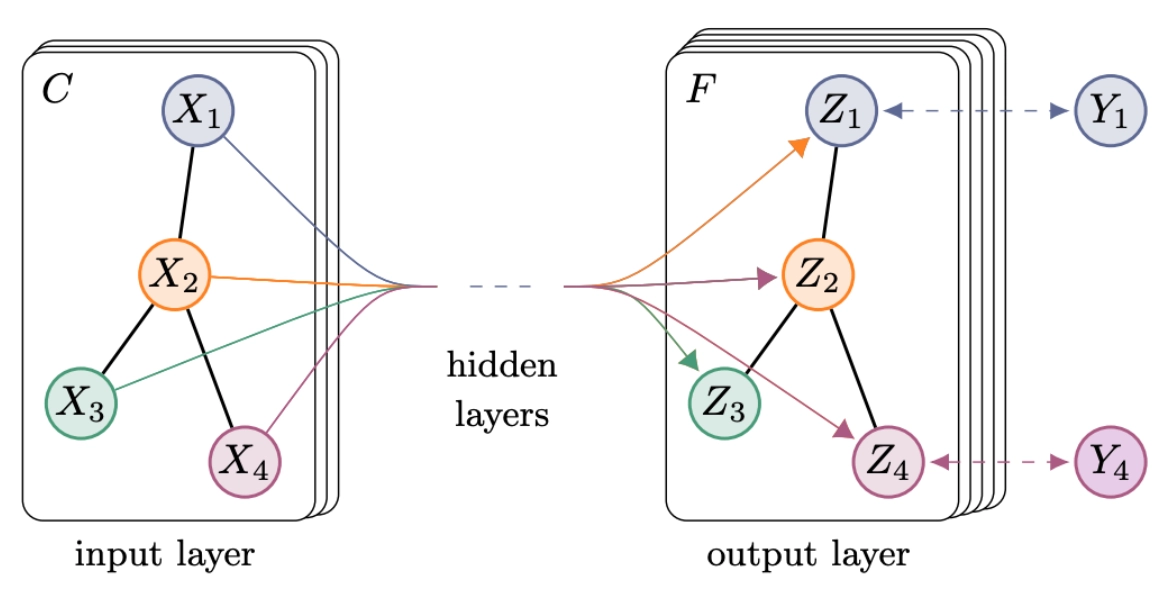 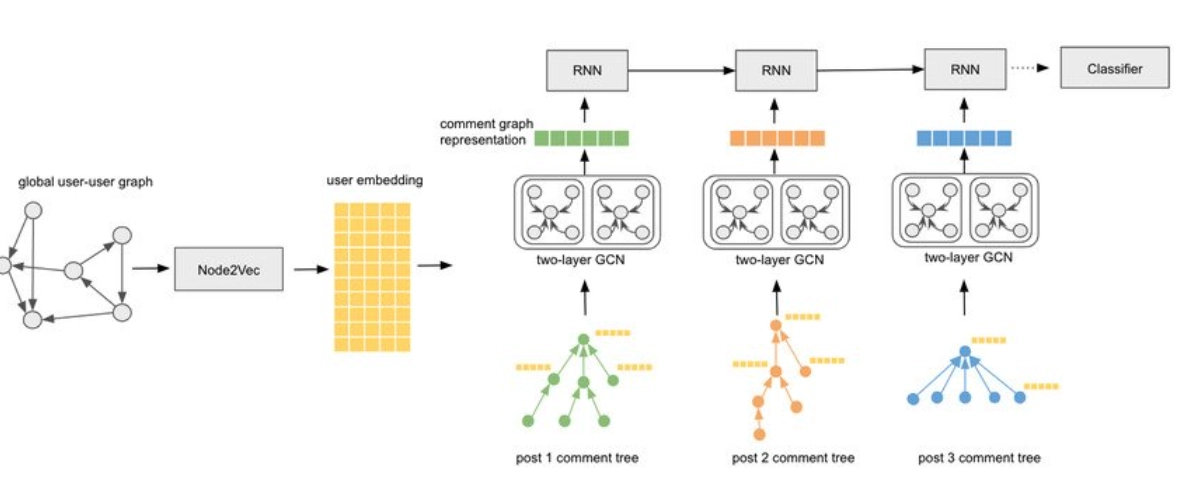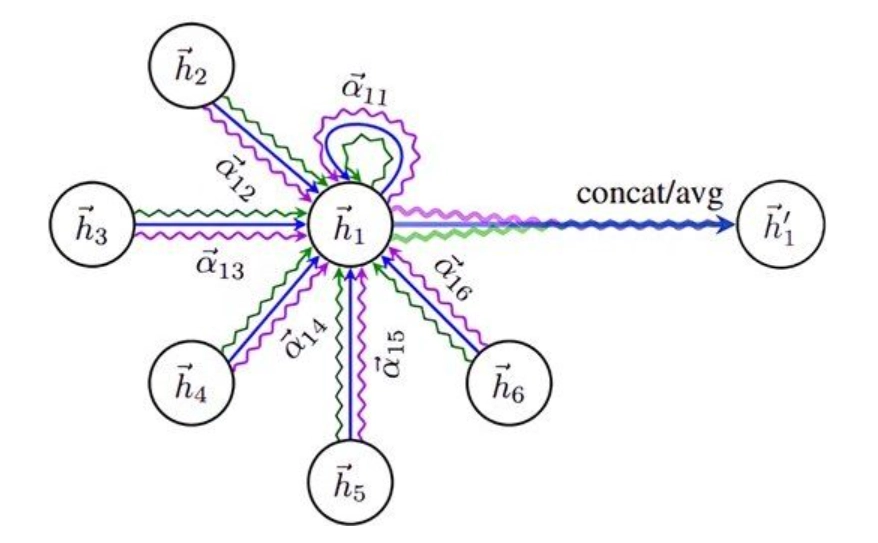 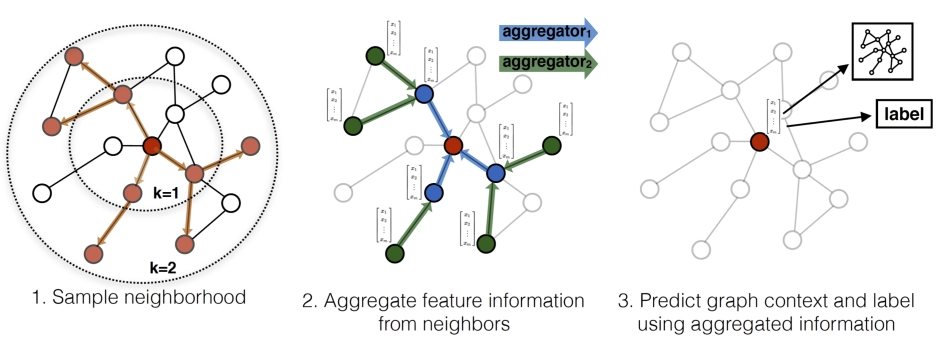
카페 사장이 "민수가 신메뉴를 주문할까?"를 친구들 의견으로 예측한다면, GNN은 친구 5명 의견을 **똑같이 평균**내는 사장이고, GAT는 **취향이 비슷한 친구 의견에 더 귀 기울이는** 사장임.

추천에서는 GCN 계열이 가장 널리 쓰이는데(GNN은 전체 개념, GCN은 합성곱으로 이웃을 집계하는 구체적인 모델), 사용자-아이템 그래프에 GCN을 적용한 **NGCF**(2019) 다음으로 이를 단순화한 **LightGCN**(2020)이 나옴. NGCF는 레이어마다 가중치 행렬 W를 곱하고 비선형 활성화 함수를 썼는데, 이건 노드에 텍스트나 속성 같은 풍부한 피처가 있을 때나 유용하고 ID 임베딩만 있는 추천에선 오히려 학습을 방해했음. 그래서 LightGCN은
1. **특징 변환 제거**: 레이어마다 있던 학습 파라미터 W 삭제
2. **비선형 활성화 함수 제거**: 정규화된 합이나 평균으로 이웃 정보만 합침 (전파 과정에서 비선형성이 이미 충분히 반영되고, 과적합도 막음)

이렇게 "정규화된 이웃 임베딩의 합 + 레이어 결합"만 남긴 결과, 같은 조건에서 NGCF보다 **평균 약 16% 높은 성능**을 보였음.

---

### 2-4. GNN 활용 사례와 장단점

> **핵심** 이웃의 이웃 정보까지 반영할 수 있지만, 층이 깊어지면 임베딩이 비슷해지고 순서는 반영하지 못함

**Pinterest**는 GNN을 추천에 적용한 대표 사례임. 핀(이미지)과 보드를 노드로, "핀이 보드에 저장됨"을 엣지로 하는 약 30억 개 노드, 180억 개 엣지의 그래프인데, 이 규모에선 전체 연산이 불가능해서 GraphSAGE처럼 중요한 이웃 일부만 샘플링해 학습함. 그 밖에 소셜 네트워크 친구 추천, 분자 구조·약물 상호작용 예측, 이상 거래 탐지, 교통 시간 예측, 코드 자동 완성 등에도 쓰임.

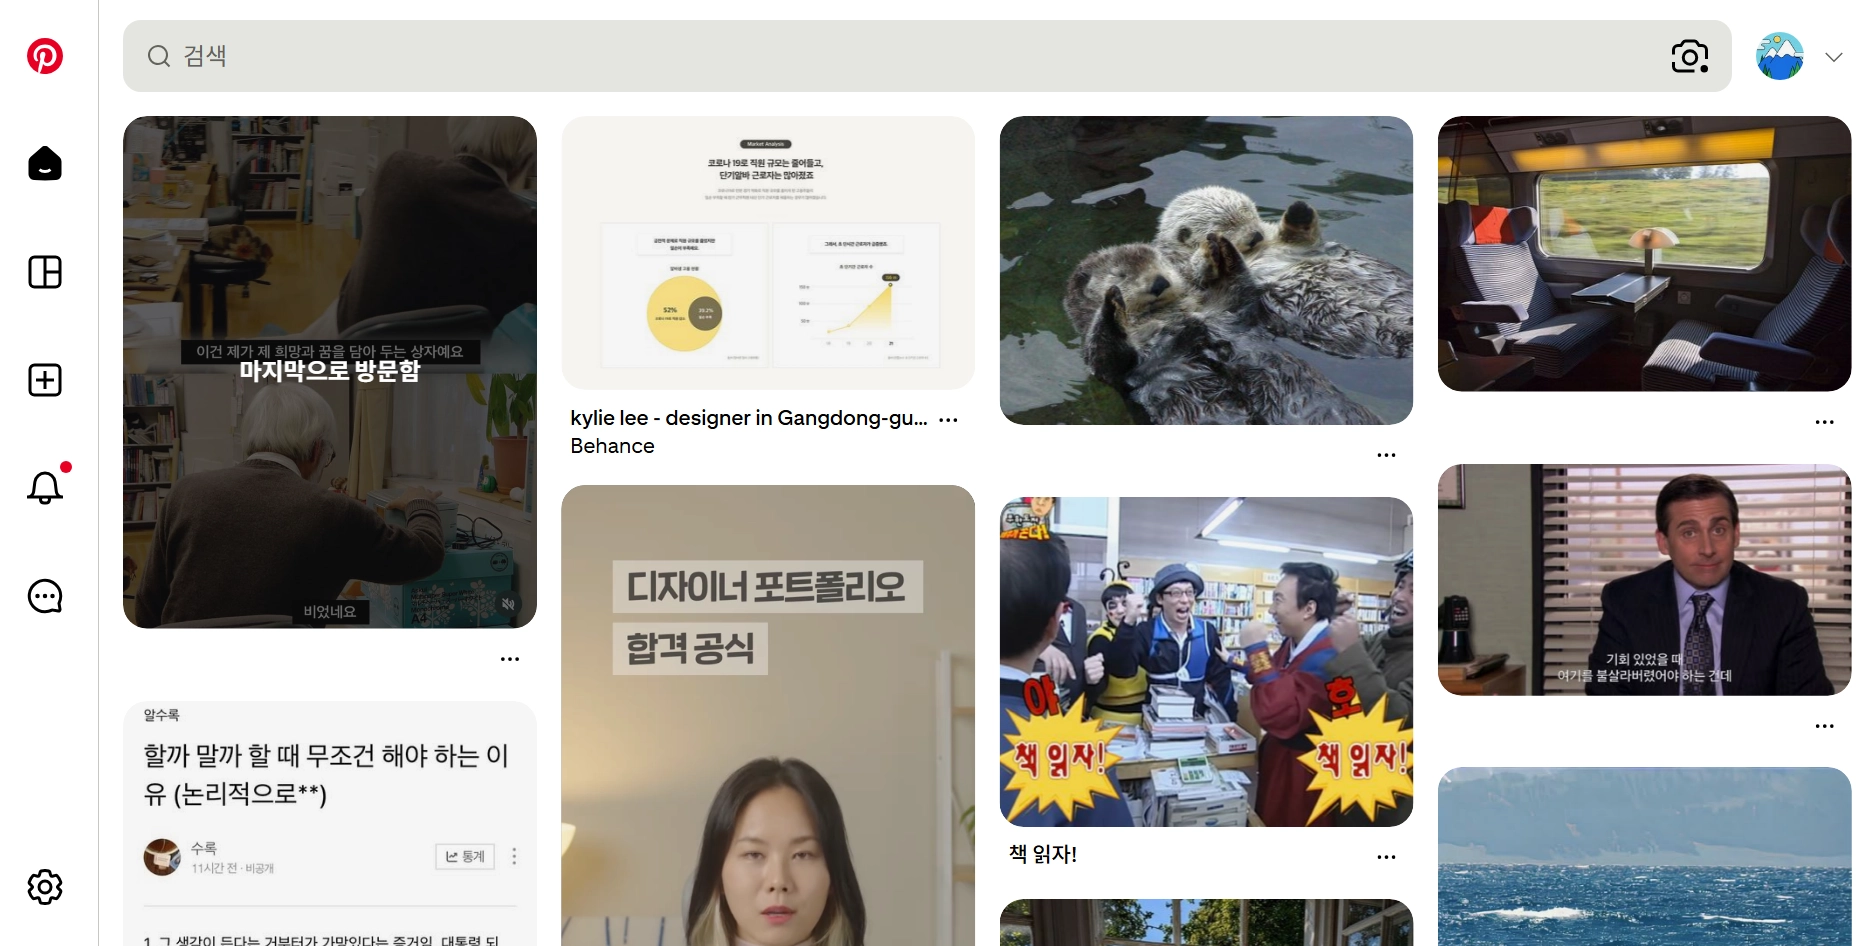

- 장점
  - 나만이 아니라 비슷한 사용자와 연관 아이템의 정보까지 반복해서 반영하는 **고차원 협업 시그널** 포착
  - 상호작용, 소셜 관계, 사용자 속성을 하나의 그래프에 담아 학습 가능
  - 신규 아이템도 속성 노드나 이웃으로 임베딩을 얻어 **콜드 스타트 완화**
- 단점
  - **과평탄화 (Over-smoothing)**: 레이어가 많아질수록 모든 노드 임베딩이 비슷해짐
  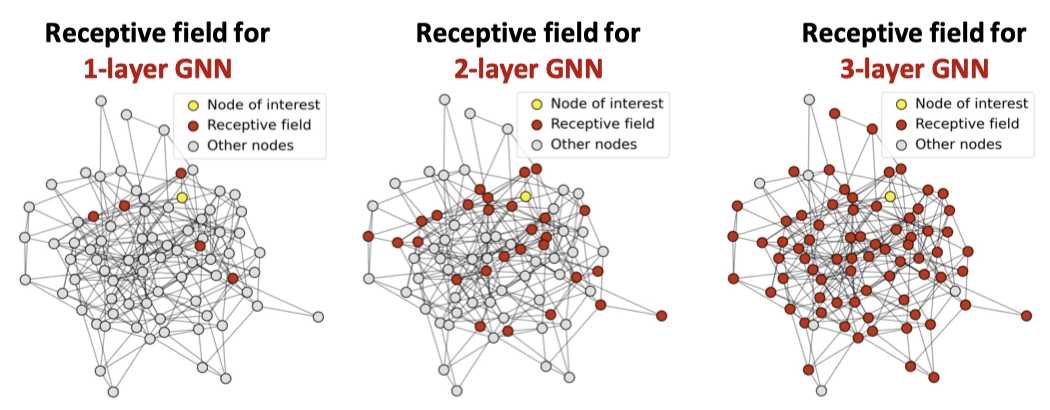
  - **과압축 (Oversquashing)**: 기하급수로 늘어나는 이웃 정보를 고정 크기 벡터에 담아 먼 노드 정보가 손실됨
  - 수십억 개 노드를 다루려면 **계산 비용**이 막대함
  - **순서 반영 X**: 신발 → 바지 → 셔츠 순서로 산 것과 반대 순서로 산 게 같은 그래프가 됨

---

## 3. Transformer 기반 추천 시스템

### 3-1. 기존 추천 시스템의 순차적 한계

> **핵심** CF는 '누가 무엇을', GNN은 '무엇이 무엇과' 연결됐는지는 잘 잡지만, '어떤 순서로, 지금 어떤 의도로'는 못 봄

- CF: 구매 순서가 달라도 같은 사용자로 보고, 방금 한 구매와 1년 전 구매를 구분 못 하고, 다음 행동보다 일반적인 선호를 예측함
- GNN: A → B → C에서 C가 A 정보를 받으려면 B를 거쳐야 해서 정보가 희석되고(과압축), 레이어 수만큼만 볼 수 있어 멀리 떨어진 행동 관계를 잡기 어려움

그래서 시퀀스 전체를 한 번에 보면서 지금 맥락에 중요한 과거 행동에 집중하는 **Transformer**가 대안으로 등장함.

---

### 3-2. Transformer -> 사용자 행동을 순서로 접근

> **핵심** 다음 행동은 장기 평균 취향보다 최근 행동의 순서와 조합(문맥)에 더 큰 영향을 받음

- **문맥에 따라 달라지는 의미**: 수영복 → 비치타월 → 선크림이면 선크림은 '휴가 준비물'이라 방수팩, 래시가드를 추천하고, 스킨 → 로션 → 선크림이면 '스킨케어 단계'라 클렌징폼, 선크림 리필을 추천함
- **시간을 뛰어넘는 핵심 의도**: 프린터 → 양말 → 라면 → 폰케이스 → 생수 → 샴푸 → ? 에서 Transformer는 거리와 상관없이 프린터에 높은 가중치를 줘서 토너를 추천함. RNN이나 GNN이면 5단계를 거치며 프린터 정보가 희석됨

---

### 3-3. Transformer의 핵심 -> Self-Attention

> **핵심** 시퀀스 안 모든 아이템 쌍의 관련성을 거리와 상관없이 동시에 계산하고, 관련성이 높은 아이템 정보를 더 많이 반영함

각 아이템 임베딩을 가중치 행렬로 Query(관련성을 계산하는 기준), Key(Query와 내적되어 점수를 결정), Value(점수에 따라 가중합되는 실제 정보)로 바꿔 씀. 연산은 `softmax(Q·Kᵀ / √d) · V`임.

EX. 선크림 기준으로
1. 선크림의 Query와 각 Key를 내적 → 수영복 2.0, 비치타월 1.5, 양말 0.1
2. Softmax로 비율 변환 → 57.0%, 34.5%, 8.5%
3. 각 Value에 비율을 곱해 더함 → 수영복과 비치타월 정보가 약 92%라 '휴가 준비물'로 해석됨

---

### 3-4. Transformer 기반 주요 추천 모델

> **핵심** SASRec은 단방향 (과거)으로 다음 아이템을, BERT4Rec은 양방향(과거 + 미래)으로 가려진 아이템을 예측함. 성능은 학습 설정 영향이 커서 상황에 따라 고름

**SASRec**
GPT처럼 **단방향** 어텐션으로 과거 아이템만 참조해 **다음 아이템을 예측**함. EX. 노트북 → 마우스 → 키보드 → 다음은 노트북 거치대. 아이템 임베딩에 위치 임베딩을 더하고, Self-Attention과 FFN을 거쳐, 출력과 아이템 임베딩을 내적해 점수를 냄.
- 특징: 데이터가 희소하면 최근 아이템에, 풍부하면 긴 과거 맥락에 집중하도록 조절하고, RNN과 달리 병렬 처리라 빠름
- 문제점: 연산량이 시퀀스 길이의 제곱에 비례하고, 과거만 봐서 앞쪽 아이템은 쓸 정보가 적음. 장바구니에 동시에 담은 것처럼 순서가 엄격하지 않은 경우도 있음
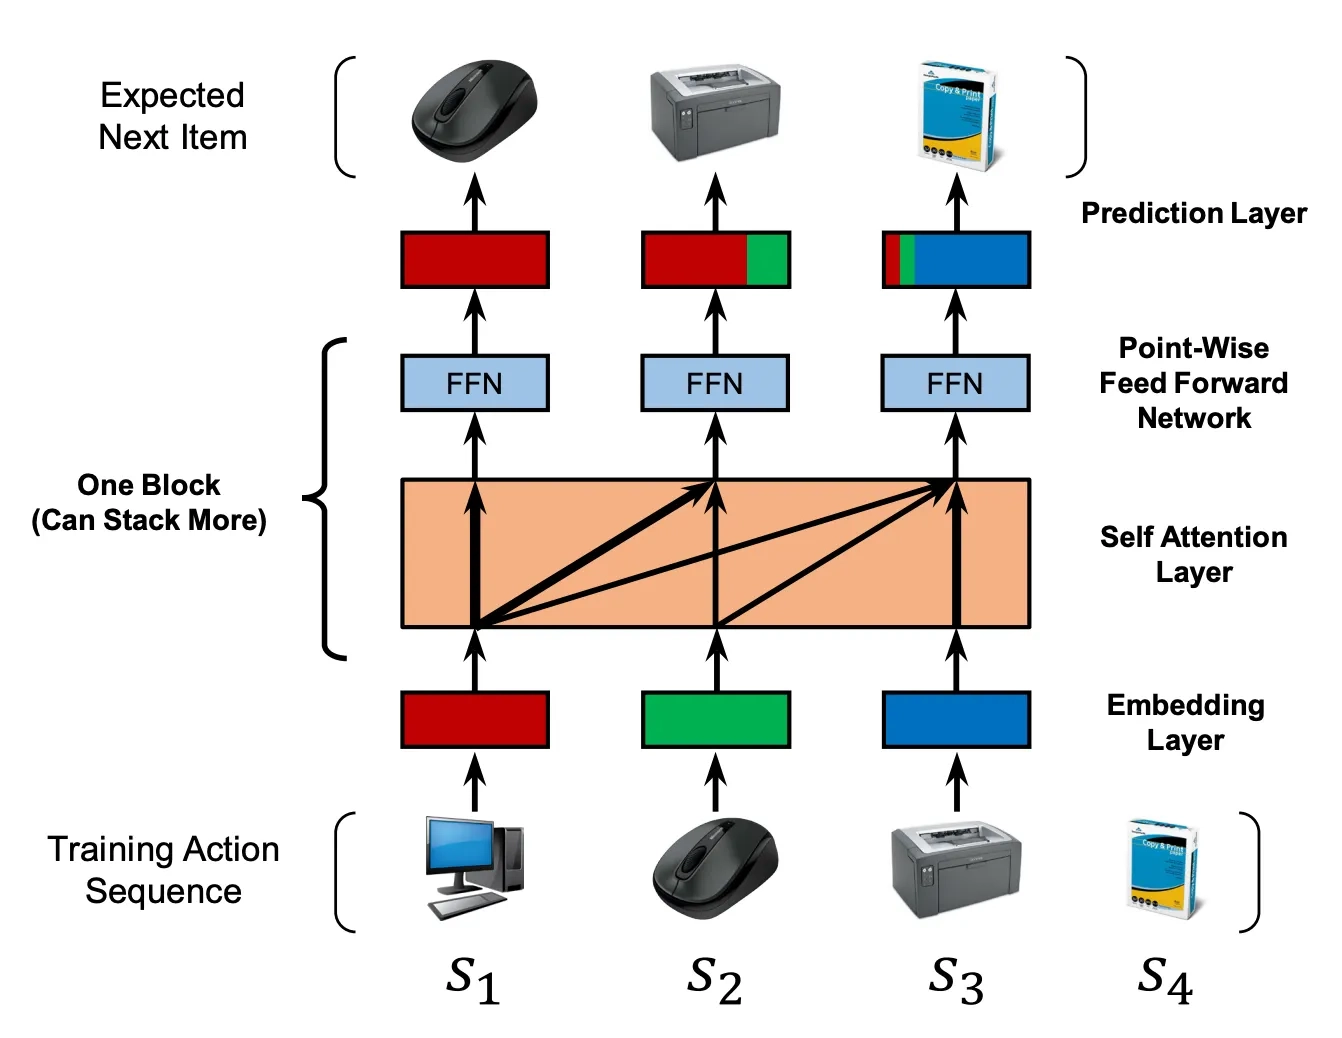
**BERT4Rec**
BERT처럼 **양방향** 어텐션으로, 시퀀스 일부를 `[MASK]`로 가리고 앞뒤 문맥으로 **가려진 아이템을 예측**함. EX. 노트북 → 마우스 → [MASK] → 키보드 → [MASK] = 노트북 거치대. 가리는 이유는 양방향으로 보면 정답 아이템을 직접 보게 되는 **정보 누출**이 생기기 때문임. 가리는 위치를 바꿔 가며 한 시퀀스로 여러 학습 샘플을 만들 수 있음.
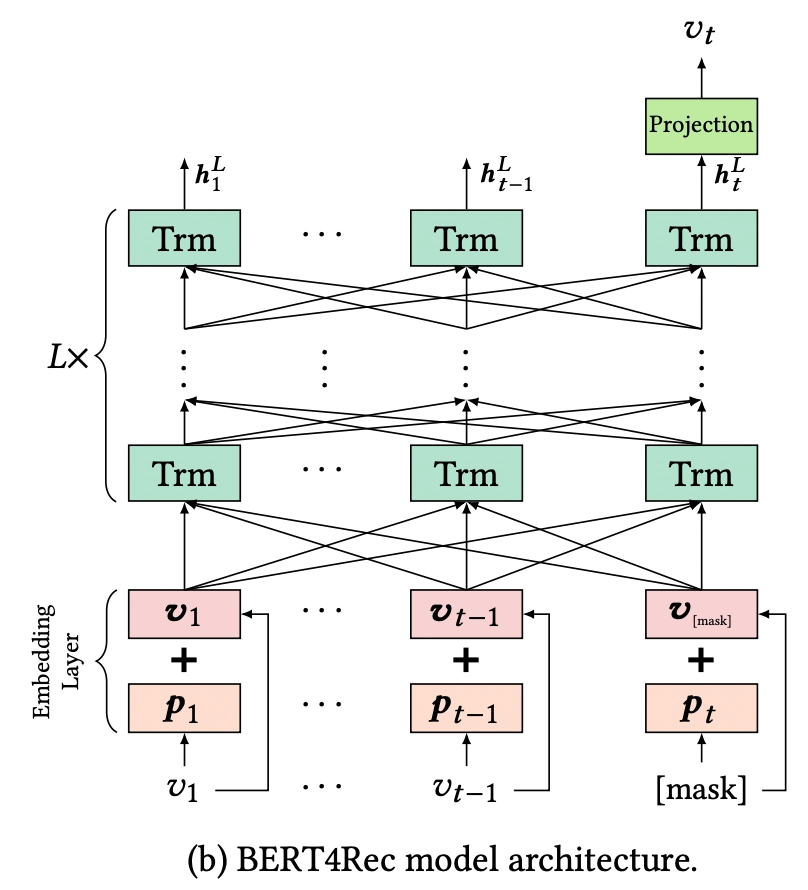

| 구분 | SASRec | BERT4Rec |
| --- | --- | --- |
| 어텐션 방향 | 단방향 (과거만) | 양방향 (과거 + 미래) |
| 학습 목표 | 다음 아이템 예측 | 가려진 아이템 예측 |
| 학습 효율 | 빠름 | 상대적으로 느림 |

원 논문(2019)에선 BERT4Rec이 더 좋다고 했지만, 후속 연구(2023)에서 손실 함수를 맞추자 SASRec이 비슷하거나 더 좋고 학습도 빨랐음(Beauty 데이터 NDCG@10 기준 0.0327 vs 0.0187). 성능 차이는 어텐션 방향보다 **학습 설정** 영향이 컸던 것임.
- 상호작용이 많고 다음 행동 예측이 목적(실시간 피드, 커머스) → SASRec
- 행동 순서가 느슨한 도메인(장바구니에 동시에 담기) → BERT4Rec
- 시퀀스가 짧은 경우 → 상황에 따라 다름 (BERT4Rec의 데이터 증강 효과 vs 손실을 맞추면 차이가 준다는 반론)

---

## 4. 제언 -> 오늘날의 추천 시스템

### 4-1. LLM의 시대

> **핵심** 추천을 점수 계산(랭킹)이 아닌 언어 문제로 풀어서, 이유를 설명하는 대화형·Zero-shot 추천이 가능해짐

과거엔 (사용자 A, 아이템 123) → 0.8점처럼 **점수**를 냈다면, LLM은 "A는 1, 2, 3을 좋아했으니 다음은 4입니다"처럼 **문장**으로 추천함. ID가 아닌 의미 기반이고 텍스트·이미지·오디오도 활용할 수 있어서, 이유를 함께 제시하는 **서술형 추천**이 가능해짐.
- **대화형 추천**: "비 오는 일요일에 혼자 보기 좋은, 너무 슬프지 않은 영화"처럼 자연어 조건을 반영함
- **Zero-shot 추천**: 구매 기록이 0건인 신상품도 설명만으로 추천 대상이 됨 → 콜드 스타트의 강력한 해결책

대표 방식은 두 가지임. **P5**(2022)는 여러 추천 과제를 "텍스트 프롬프트 → 텍스트 답변"으로 통일해 하나의 언어 모델로 학습했지만 처음부터 학습해서 자원이 많이 듦. **TALLRec**(2023)은 범용 LLM을 "좋아할까? (Yes/No)" 지시문으로 튜닝하고 LoRA로 일부만 학습해서, 적은 샘플로도 기존 모델보다 높은 성능을 보고했음.

---

### 4-2. 인기 편향과 XAI 문제

> **핵심** 모델이 정교해져도 무엇을 추천하는가(인기 편향)와 왜 추천하는가(설명 가능성)의 문제는 남음

**인기 편향**은 소수 인기 아이템이 추천을 독점하는 현상으로, 데이터 불균형 → 데이터 많은 아이템일수록 점수가 높아 더 추천됨 → 추천·노출·클릭·학습이 반복되며 격차가 커지는 **Rich-get-richer** 순서로 강화됨. 넷플릭스 프라이즈 데이터에선 인기 영화 16.5%가 평점의 약 86%를 차지했고, Spotify 팟캐스트 실험에선 개인화 추천으로 스트리밍은 28.90% 늘었지만 개인의 소비 다양성은 11.51% 줄었음.

**설명 가능성(XAI)**은 왜 이걸 추천했는지 설명할 수 있느냐의 문제임. GNN, Transformer는 강력하지만 **블랙박스**라서 고객과 비즈니스 담당자에게 근거를 제시하기 어려움. LLM은 이유를 자연어로 만들 수 있지만, 그 설명이 실제 추천 근거와 일치한다는 보장은 없음.

---

### 4-3. 컴퓨팅 자본과 Cold-Start를 고려한 도입

> **핵심** 모든 아이템에 딥러닝을 쓰기엔 너무 비싸서, 현업에선 선형 모델로 후보를 거르고 딥러닝으로 정렬하는 2단계 구조를 씀

딥러닝은 GPU 비용, 요청마다 전체 아이템을 계산하는 서버비, 사용자 × 요청 수만큼 매일 쌓이는 비용 때문에 전면 도입이 부담됨. 그래서 유튜브, 아마존 같은 현업에선
1. **후보군 생성**: 수백만 개 → 수백 개로 축소. 빠르고 저렴한 **선형 모델**(내용 기반, 협업 필터링, 행렬 분해) 사용
2. **순위 매기기**: 수백 개 후보를 정교하게 정렬해 상위 수십 개 노출. 비선형성, 순서, 관계까지 활용하는 **딥러닝 모델**(GNN, Transformer, VAE) 사용

결국! 실제 추천 시스템은 단일 모델이 아니라, 지금까지 배운 모델들을 단계별로 조합해 비용과 정확도를 함께 챙기는 구조임.

